# No-look-ahead backtest with a real futures short: long spot into D, short the single-stock future after D

**The problem.** `backtest_noahead.ipynb` flips to short at the close of D using **stock returns**. D is the first day
of the margin-short ban (停止融券賣出), so a new spot short cannot be placed then. The short leg is only placeable
through single-stock futures (or SBL), and only about a third of Q5 events have a listed future at the time.

**The fix.** Same events, signal, timing and hedge as `backtest_noahead.ipynb` (set D: MOPS ex-div postings + AGM
postings public before the entry close), but:

* **Universe:** only events whose stock had a single-stock future **listed on TAIFEX by the entry (close of D−6)** and
  still listed through D+5. Listing dates come from TAIFEX's daily download, which also covers futures delisted since
  (`collect_taifex_futures.py`), not from today's list in `futures_map.csv`.
* **Long leg:** buy the **stock** at the close of D−6, sell at the close of D (spot; selling a long is never banned).
* **Short leg:** sell the **single-stock future** at the close of D, buy it back at the close of D+5, at TAIFEX
  settlement prices.
* **Hedge:** each leg beta-hedged with TAIEX futures, as before.

**Kept from `backtest_noahead.ipynb`:** K = 6, H = 5; Q5 = days-to-cover on D−17 ≥ expanding 80th percentile of past
deadline events; 20-day turnover ≥ NT$20m; Dimson beta on the 250 days ending D−17, Blume-shrunk; β×2bp hedge cost;
fixed notional per trade; same in/out-of-sample split.

**Costs.** The headline charges the long spot leg **55bp** round trip (30bp sell tax + commission + slippage, as in
`backtest_spot.ipynb`) and the futures short **20bp** round trip (futures tax 0.2bp per side, commission, spread; the
per-leg cost `backtest_noahead.ipynb` used for everything). A 20bp / 20bp run is shown too for a like-for-like
comparison with `backtest_noahead.ipynb`.

**Look-ahead checklist (additions to `backtest_noahead.ipynb`)**

| Input | Known by the entry (close of D−6)? |
|---|---|
| The stock has a listed future | Yes: first TAIFEX trading date ≤ D−6 (new underlyings are announced about a month before listing) |
| Futures delisted since | Included: codes missing from today's TAIFEX list are matched to their stock by price |
| Which futures code (regular vs mini) | The code with the most volume over the 20 days ending D−6 |
| Which contract month | Nearest month whose last trading day is after D+5 (the expiry calendar is fixed: 3rd Wednesday) |
| Dividend in the short window | Ex-div events have ex-date D+4. TAIFEX converts open positions into an adjusted contract carrying the dividend, so the short's return is F_t / (F_t−1 × adj) − 1, with adj the stock's ex-date factor |

## 1. Data
**What this does.** Same TWSE panel, signal inputs, TAIEX hedge return and MOPS announcements as
`backtest_noahead.ipynb`, plus the TAIFEX single-stock futures panel and listing dates.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
K, H = 6, 5                  # as backtest_noahead.ipynb: long from the close of D-6 to D, short from the close of D to D+5
Q5_PCT, Q5_MIN_HIST = 0.80, 200   # Q5 cutoff: expanding 80th pct of days-to-cover over past events; burn-in of 200 events
SIG_LAG, MIN_VAL20, COST_LEG_BPS = 17, 2e7, 20
COST_SPOT_LONG_BPS, COST_FUT_SHORT_BPS = 55, 20
K_LABEL, H_LABEL = 12, 20    # in/out-of-sample split exactly as backtest_noahead.ipynb
BETA_WIN, BETA_MIN, DIMSON_LAGS = 250, 60, 2
HEDGE_BPS, RF = 2, 0.015
EX_TO_D = 4                  # D = ex-date - 4 trading days
CLOSE_AUCTION = "13:25:00"   # an announcement must be posted before this on the entry day
FUT_VOL_WIN, MIN_FUT_ADV = 20, 50   # futures code choice window; liquidity sensitivity (contracts / day)

is_stock = lambda s: s.str.fullmatch(r"[1-9]\d{3}")
px = pd.read_csv(DATA / "prices.csv", dtype={"stock_id": str}, parse_dates=["date"])
px = px[is_stock(px.stock_id)].drop_duplicates(["date", "stock_id"]).sort_values(["stock_id", "date"])
exd = pd.read_csv(DATA / "exdiv.csv", dtype={"stock_id": str}, parse_dates=["date"])
exd = exd.dropna(subset=["close_before", "ref_price"]).drop_duplicates(["date", "stock_id"])
exd["adj"] = exd.ref_price / exd.close_before
px = px.merge(exd[["date", "stock_id", "adj"]], on=["date", "stock_id"], how="left")
px["adj"] = px["adj"].fillna(1.0)
px["close_ff"] = px.groupby("stock_id")["close"].ffill()
px["ret"] = px.close / (px.groupby("stock_id")["close_ff"].shift() * px.adj) - 1
px.loc[px.ret.abs() > 0.105, "ret"] = np.nan

idx = pd.read_csv(DATA / "index.csv", parse_dates=["date"]).drop_duplicates("date").sort_values("date").set_index("date")
cal = idx.index
mg = pd.read_csv(DATA / "margin.csv", dtype={"stock_id": str}, parse_dates=["date"])
mg = mg[is_stock(mg.stock_id)].drop_duplicates(["date", "stock_id"])
stocks = pd.Index(sorted(set(px.stock_id) & set(mg.stock_id)))
wide = lambda df, c: df.pivot(index="date", columns="stock_id", values=c).reindex(index=cal, columns=stocks)
R = wide(px, "ret")
ADJ = wide(px, "adj").fillna(1.0).values
SB = wide(mg, "short_bal")
ADV = (wide(px, "volume") / 1000).rolling(20, min_periods=10).mean()
VAL20 = wide(px, "value").rolling(20, min_periods=10).mean()
col = {s: i for i, s in enumerate(stocks)}
T = len(cal); Rv = R.values
CUT = int(T * 2 / 3)
taiex = idx.taiex_tr.pct_change(fill_method=None).fillna(0).values
HEDGE_R = taiex - RF / 252

mops = pd.read_csv(DATA / "mops_exdiv.csv", dtype={"stock_id": str, "announce_time": str},
                   parse_dates=["ex_rights_date", "ex_div_date", "announce_date"])

fl = pd.read_csv(DATA / "futures_listing_pit.csv", dtype={"stock_id": str}, parse_dates=["first", "last"])
fu = pd.read_csv(DATA / "taifex_stock_futures.csv", dtype={"stock_id": str, "contract_date": str}, parse_dates=["date"])
fu["di"] = cal.get_indexer(fu.date)
fu = fu[fu.di >= 0]
print(f"{T} trading days {cal[0].date()} -> {cal[-1].date()}; out-of-sample from {cal[CUT].date()}")
print(f"TAIFEX: {len(fl)} stock / ETF futures codes since 2018 ({(fl.mapped_by == 'price match').sum()} delisted, price-matched); "
      f"panel {len(fu):,} rows on {fu.stock_id.nunique()} TWSE stocks")

2122 trading days 2018-01-02 -> 2026-09-23; out-of-sample from 2023-10-26
TAIFEX: 348 stock / ETF futures codes since 2018 (29 delisted, price-matched); panel 2,380,856 rows on 275 TWSE stocks


## 2. Events (set D of `backtest_noahead.ipynb`)
**What this does.** Rebuilds set D exactly as `backtest_noahead.ipynb`: ex-div / ex-rights events from MOPS postings
(D = ex-date − 4 trading days) public before the close of D−6, plus AGM deadlines from `suspension.csv` whose MOPS
posting was public by then; Q5 cutoff over past events only; liquidity filter on D−17.

In [2]:
m = mops[mops.stock_id.isin(stocks)].copy()
m["ex"] = m[["ex_rights_date", "ex_div_date"]].min(axis=1)
m = m.dropna(subset=["ex", "announce_date"])
ex_i = cal.searchsorted(m.ex.values)
m = m[(ex_i < T) & (ex_i >= EX_TO_D)]
m["D"] = cal.searchsorted(m.ex.values) - EX_TO_D
m["announce_time"] = m.announce_time.fillna("23:59:59").str.strip()
m = m.sort_values(["stock_id", "D", "announce_date", "announce_time"])
m["grp"] = (m.groupby("stock_id").D.diff().fillna(99) >= 10).cumsum()
ev = m.groupby("grp").agg(stock_id=("stock_id", "first"), D=("D", "first"),
                          announce_date=("announce_date", "first"), announce_time=("announce_time", "first")).reset_index(drop=True)
ev = ev.sort_values(["stock_id", "D"])
ev = ev[ev.groupby("stock_id").D.diff().fillna(99) >= 10].reset_index(drop=True)

sus = pd.read_csv(DATA / "suspension.csv", dtype={"stock_id": str}, parse_dates=["date", "end_date"]).drop_duplicates()
sus["D"] = cal.searchsorted(sus.date.values)

pool = sus[sus.stock_id.isin(stocks) & (sus.D >= SIG_LAG) & (sus.D < T)].sort_values(["stock_id", "D"])
pool = pool[pool.groupby("stock_id").D.diff().fillna(99) >= 10]
pj, ps = pool.stock_id.map(col).values, pool.D.values - SIG_LAG
pool = pd.DataFrame({"D": pool.D.values, "dtc": SB.values[ps, pj] / ADV.values[ps, pj], "sb": SB.values[ps, pj]})
pool = pool[(pool.sb > 0) & np.isfinite(pool.dtc)].sort_values("D")
POOL_D, POOL_X = pool.D.values, pool.dtc.values

def q5_cutoff(s):
    n = np.searchsorted(POOL_D, s, side="left")
    return np.quantile(POOL_X[:n], Q5_PCT) if n >= Q5_MIN_HIST else np.nan

THR_BY_S = {s: q5_cutoff(s) for s in range(T)}

def signal(df):
    df = df[(df.D >= SIG_LAG + 1) & (df.D + H + 1 < T)].copy()
    df["j"] = df.stock_id.map(col)
    s_ = df.D.values - SIG_LAG
    df["sb"] = SB.values[s_, df.j.values]
    df["dtc"] = df.sb / ADV.values[s_, df.j.values]
    df["val20"] = VAL20.values[s_, df.j.values]
    df["thr"] = [THR_BY_S[s] for s in s_]
    df["Ddate"] = cal[df.D.values]
    df["period"] = np.select([df.D + H_LABEL < CUT, df.D - K_LABEL >= CUT], ["in-sample", "out-of-sample"], "boundary")
    return df[(df.sb > 0) & (df.dtc >= df.thr) & (df.val20 >= MIN_VAL20) & (df.period != "boundary")].reset_index(drop=True)

sa = sus[sus.stock_id.isin(stocks)].copy()
sa = sa[(sa.D >= SIG_LAG + 1) & (sa.D + H + 1 < T)].sort_values(["stock_id", "D"])
sa = sa[sa.groupby("stock_id").D.diff().fillna(99) >= 10]
A = signal(sa[["stock_id", "D", "reason"]])

B = signal(ev)
B["entry_date"] = cal[B.D.values - K]
B["known"] = (B.announce_date < B.entry_date) | ((B.announce_date == B.entry_date) & (B.announce_time < CLOSE_AUCTION))
C = B[B.known].reset_index(drop=True)

AG = A[A.reason == "股東常會"].copy()
agm = pd.read_csv(DATA / "mops_agm.csv", dtype={"stock_id": str}, parse_dates=["D"])
agm["D"] = cal.searchsorted(agm.D.values)
AG = AG.merge(agm.drop_duplicates(["stock_id", "D"])[["stock_id", "D", "matched", "lead"]], on=["stock_id", "D"], how="left")
AG["known"] = AG.matched.eq(True) & (AG.lead >= K)
C["src"], AG["src"] = "ex-div", "AGM"
COLS = ["stock_id", "D", "j", "Ddate", "period", "src"]
DD = pd.concat([C[COLS], AG.loc[AG.known, COLS]], ignore_index=True)
print("set D events (Q5, liquid, public by the entry):", DD.groupby("period").size().to_dict(), "| by source:", DD.src.value_counts().to_dict())

set D events (Q5, liquid, public by the entry): {'in-sample': 738, 'out-of-sample': 224} | by source: {'AGM': 567, 'ex-div': 395}


## 3. Which events had a future at the time, and which contract to trade
**What this does.** For each set-D event:

1. **Listed?** Keeps the stock's futures codes whose first TAIFEX trading date is on or before the entry (D−6) and whose
   last is on or after D+5.
2. **Code:** the listed code with the most volume over the 20 trading days ending D−6 (regular vs mini).
3. **Contract month:** the nearest month whose last trading day is after D+5, so the short never rolls or runs into
   expiry.
4. **Short-leg return** on D+1…D+5: settlement-price return of that contract, divided by the stock's ex-date
   factor on the ex-date (D+4 for ex-div events), i.e. F_t / (F_t−1 × adj_t) − 1.

Events with no settlement price on D (contract not quoted) are dropped as untradable. The table compares this
point-in-time count with the naive check against today's TAIFEX list.

In [3]:
fvol = fu.groupby(["futures_id", "di"]).volume.sum().unstack(0).reindex(range(T)).fillna(0)
fadv = fvol.rolling(FUT_VOL_WIN, min_periods=1).mean()
expiry = fu.groupby(["futures_id", "contract_date"]).di.max()          # last trading day of each contract month
settle = {k: g.set_index("di").settle for k, g in fu[fu.settle > 0].groupby(["futures_id", "contract_date"])}
cvol = {k: g.set_index("di").volume for k, g in fu.groupby(["futures_id", "contract_date"])}
codes_by_stock = {s: g for s, g in fl.groupby("stock_id")}
now_list = set(pd.read_csv(DATA / "futures_map.csv", dtype=str).stock_id)

def pick_future(sid, D, j):
    g = codes_by_stock.get(sid)
    if g is None:
        return None, "no future ever"
    g = g[(g["first"] <= cal[D - K]) & (g["last"] >= cal[D + H])]
    if g.empty:
        return None, "not listed at entry"
    fid = max(g.futures_id, key=lambda x: fadv.at[D - K, x] if x in fadv else -1)
    months = expiry.loc[fid]
    months = months[months > D + H].index
    for cm in sorted(months):
        p = settle.get((fid, cm))
        if p is None or D not in p.index:
            continue
        p = p.reindex(range(D, D + H + 1)).ffill().values
        r = p[1:] / (p[:-1] * ADJ[D + 1:D + H + 1, j]) - 1
        v = cvol[(fid, cm)].reindex([D, D + H]).fillna(0).values
        return dict(fid=fid, cm=cm, fut_r=r, fut_adv20=fadv.at[D - K, fid], vol_D=v[0], vol_DH=v[1]), "ok"
    return None, "no quote on D"

res = [pick_future(s, d, j) for s, d, j in zip(DD.stock_id, DD.D, DD.j)]
DD["fut_status"] = [st for _, st in res]
DD["naive_listed"] = DD.stock_id.isin(now_list)
F = DD[DD.fut_status == "ok"].reset_index(drop=True)
info = pd.DataFrame([r for r, st in res if st == "ok"])
F = pd.concat([F, info], axis=1)
FUT_R = np.vstack(F.fut_r.values)

tab = pd.DataFrame({"events": DD.groupby("period").size(),
                    "future listed at entry (traded here)": F.groupby("period").size(),
                    "naive: in today's TAIFEX list": DD[DD.naive_listed].groupby("period").size()})
tab["share traded"] = (tab.iloc[:, 1] / tab.events).round(3)
tab["share naive"] = (tab.iloc[:, 2] / tab.events).round(3)
print(tab.to_string())
print("\nstatus of all set-D events:", DD.fut_status.value_counts().to_dict())
print(f"naive list says yes but not listed at entry: {(DD.naive_listed & (DD.fut_status != 'ok')).sum()} events; "
      f"listed at entry but missing from today's list (delisted since): {(~DD.naive_listed & (DD.fut_status == 'ok')).sum()}")
print(f"\ntraded events: {len(F)} on {F.stock_id.nunique()} stocks, {F.Ddate.nunique()} deadline dates; by source {F.src.value_counts().to_dict()}")
print("futures volume, contracts/day (20 days to D-6, chosen code):",
      F.fut_adv20.describe(percentiles=[.1, .25, .5, .75]).round(0).drop("count").to_dict())
print(f"chosen contract traded on D: {(F.vol_D > 0).mean():.0%}, on D+{H}: {(F.vol_DH > 0).mean():.0%}; "
      f"futures ADV20 >= {MIN_FUT_ADV}: {(F.fut_adv20 >= MIN_FUT_ADV).mean():.0%}")

               events  future listed at entry (traded here)  naive: in today's TAIFEX list  share traded  share naive
period                                                                                                               
in-sample         738                                   234                            286         0.317        0.388
out-of-sample     224                                    50                             53         0.223        0.237

status of all set-D events: {'no future ever': 612, 'ok': 284, 'not listed at entry': 66}
naive list says yes but not listed at entry: 59 events; listed at entry but missing from today's list (delisted since): 4

traded events: 284 on 107 stocks, 158 deadline dates; by source {'AGM': 173, 'ex-div': 111}
futures volume, contracts/day (20 days to D-6, chosen code): {'mean': 1269.0, 'std': 2755.0, 'min': 3.0, '10%': 61.0, '25%': 148.0, '50%': 467.0, '75%': 1083.0, 'max': 25646.0}
chosen contract traded on D: 100%, on D+5: 99

## 4. Futures vs stock on the short leg
**What this does.** Checks the futures returns against the stock returns the earlier notebooks used, day by day on the
short window. The ex-date rows (ex-div events, D+4) test the dividend adjustment: without it the futures short would
book the whole dividend as profit.

daily futures vs stock return on D+1..D+5: corr 0.973, median |diff| 33bp, mean diff +4.9bp
ex-date rows in the short window: 113; median |futures - stock|: adjusted 40bp, unadjusted 393bp (the dividend)


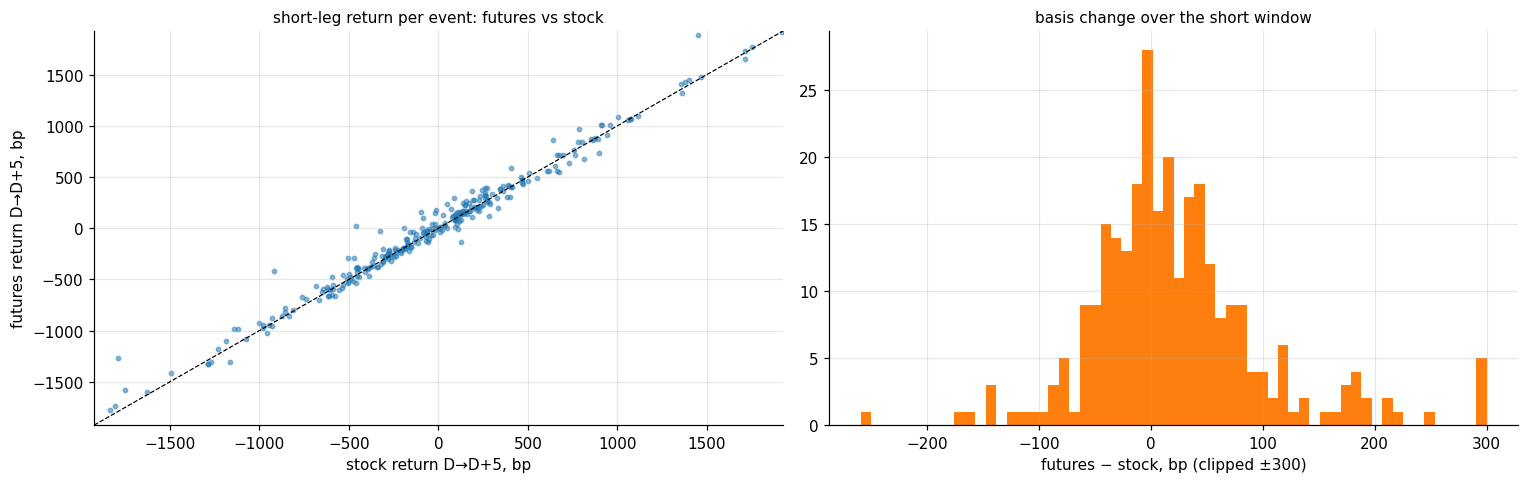

        futures − stock, mean bp  median bp
AGM                         29.6       13.9
ex-div                      16.9        0.4


In [4]:
SR = Rv[F.D.values[:, None] + np.arange(1, H + 1)[None, :], F.j.values[:, None]]
ok = np.isfinite(SR) & np.isfinite(FUT_R)
d = (FUT_R - SR)[ok]
print(f"daily futures vs stock return on D+1..D+{H}: corr {np.corrcoef(FUT_R[ok], SR[ok])[0, 1]:.3f}, "
      f"median |diff| {np.median(np.abs(d)) * 1e4:.0f}bp, mean diff {d.mean() * 1e4:+.1f}bp")
exm = ADJ[F.D.values[:, None] + np.arange(1, H + 1)[None, :], F.j.values[:, None]] < 0.9999
raw = (1 + FUT_R) * ADJ[F.D.values[:, None] + np.arange(1, H + 1)[None, :], F.j.values[:, None]] - 1
e = exm & ok
print(f"ex-date rows in the short window: {e.sum()}; median |futures - stock|: adjusted {np.median(np.abs(FUT_R - SR)[e]) * 1e4:.0f}bp, "
      f"unadjusted {np.median(np.abs(raw - SR)[e]) * 1e4:.0f}bp (the dividend)")

leg_f, leg_s = FUT_R.sum(1), np.nan_to_num(SR).sum(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(leg_s * 1e4, leg_f * 1e4, s=8, alpha=.5)
lim = np.nanpercentile(np.abs(np.r_[leg_s, leg_f]) * 1e4, 99)
ax[0].plot([-lim, lim], [-lim, lim], "k--", lw=.8); ax[0].set_xlim(-lim, lim); ax[0].set_ylim(-lim, lim)
ax[0].set_xlabel(f"stock return D→D+{H}, bp"); ax[0].set_ylabel(f"futures return D→D+{H}, bp")
ax[0].set_title("short-leg return per event: futures vs stock", fontsize=10)
ax[1].hist(((leg_f - leg_s) * 1e4).clip(-300, 300), bins=60, color="C1")
ax[1].set_xlabel("futures − stock, bp (clipped ±300)"); ax[1].set_title("basis change over the short window", fontsize=10)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"futures − stock, mean bp": pd.Series((leg_f - leg_s) * 1e4).groupby(F.src.values).mean(),
                    "median bp": pd.Series((leg_f - leg_s) * 1e4).groupby(F.src.values).median()}).round(1).to_string())

## 5. Beta and the P&L engine
**What this does.** Same as `backtest_noahead.ipynb`: Dimson beta (lags 0–2) on the 250 days ending D−17,
Blume-shrunk, β = 1 with fewer than 60 usable days. Each trade holds +1 stock / −β TAIEX futures on D−5…D, then
−1 short leg / +β TAIEX futures on D+1…D+5. The short leg is the stock (as before) or the single-stock future. The
long leg's cost plus β×2bp is charged on D, the short leg's cost plus β×2bp on D+5. Fixed notional per trade.

Runs, each one step from the last:

1. **backtest_noahead headline:** all set-D events, stock short, 20bp / 20bp.
2. **Futures subset, stock short:** only events with a future listed at entry. 1 → 2 is the selection effect.
3. **Futures subset, futures short, 20bp / 20bp.** 2 → 3 is the futures-vs-stock basis.
4. **Headline: long spot 55bp, short futures 20bp.** 3 → 4 is the spot cost on the long leg.
5. **Headline, liquid futures only** (futures volume ≥ 50 contracts/day over the 20 days to D−6).

In [5]:
M_LAGS = np.column_stack([np.r_[np.full(k, np.nan), taiex[:T - k]] for k in range(DIMSON_LAGS + 1)])

def beta(j, end):
    rows = slice(max(0, end - BETA_WIN + 1), end + 1)
    y, X = Rv[rows, j], M_LAGS[rows]
    ok = np.isfinite(y) & np.isfinite(X).all(1) & (np.abs(y) < 0.095)
    if ok.sum() < BETA_MIN:
        return 1.0
    b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), X[ok]]), y[ok], rcond=None)[0][1:].sum()
    return 0.67 * b + 0.33

OFF = np.arange(-K + 1, H + 1)
SIGN = np.where(OFF <= 0, 1.0, -1.0)
hcost = HEDGE_BPS / 1e4

def book(df, fut_r=None, c_long=COST_LEG_BPS, c_short=COST_LEG_BPS, hedged=True):
    b = np.array([beta(j, d - SIG_LAG) for j, d in zip(df.j.values, df.D.values)]) * hedged
    days = df.D.values[:, None] + OFF[None, :]
    rs = np.nan_to_num(Rv[days, df.j.values[:, None]])
    if fut_r is not None:
        rs[:, OFF >= 1] = np.nan_to_num(fut_r)
    pnl = SIGN[None, :] * (rs - b[:, None] * HEDGE_R[days])
    pnl[:, OFF == 0] -= (c_long / 1e4 + np.abs(b) * hcost)[:, None]
    pnl[:, OFF == H] -= (c_short / 1e4 + np.abs(b) * hcost)[:, None]
    s = np.zeros(T); c = np.zeros(T)
    np.add.at(s, days.ravel(), pnl.ravel()); np.add.at(c, days.ravel(), 1)
    return {"fixed": pd.Series(s, cal), "npos": pd.Series(c, cal), "net": pnl.sum(1),
            "long": pnl[:, OFF <= 0].sum(1), "short": pnl[:, OFF >= 1].sum(1), "beta": b}

sharpe = lambda d: d.mean() / d.std() * np.sqrt(252) if d.std() > 0 else np.nan
LIQ = (F.fut_adv20 >= MIN_FUT_ADV).values
FL = F[LIQ].reset_index(drop=True)
HEAD = "4 long spot 55bp + short futures 20bp (headline)"
SETS = {"1 all set D, stock short (backtest_noahead)": (DD, None, COST_LEG_BPS, COST_LEG_BPS),
        "2 futures listed at entry, stock short": (F, None, COST_LEG_BPS, COST_LEG_BPS),
        "3 futures listed, futures short, 20bp / 20bp": (F, FUT_R, COST_LEG_BPS, COST_LEG_BPS),
        HEAD: (F, FUT_R, COST_SPOT_LONG_BPS, COST_FUT_SHORT_BPS),
        f"5 headline, futures ADV20 >= {MIN_FUT_ADV}": (FL, FUT_R[LIQ], COST_SPOT_LONG_BPS, COST_FUT_SHORT_BPS)}
RUNS = {nm: book(df, fr, cl, cs) for nm, (df, fr, cl, cs) in SETS.items()}
H_UNH = book(F, FUT_R, COST_SPOT_LONG_BPS, COST_FUT_SHORT_BPS, hedged=False)

## 6. P&L
**What this does.** Cumulative fixed-notional P&L for the five runs, out-of-sample shaded. Then the headline split
into legs, and hedged vs unhedged.

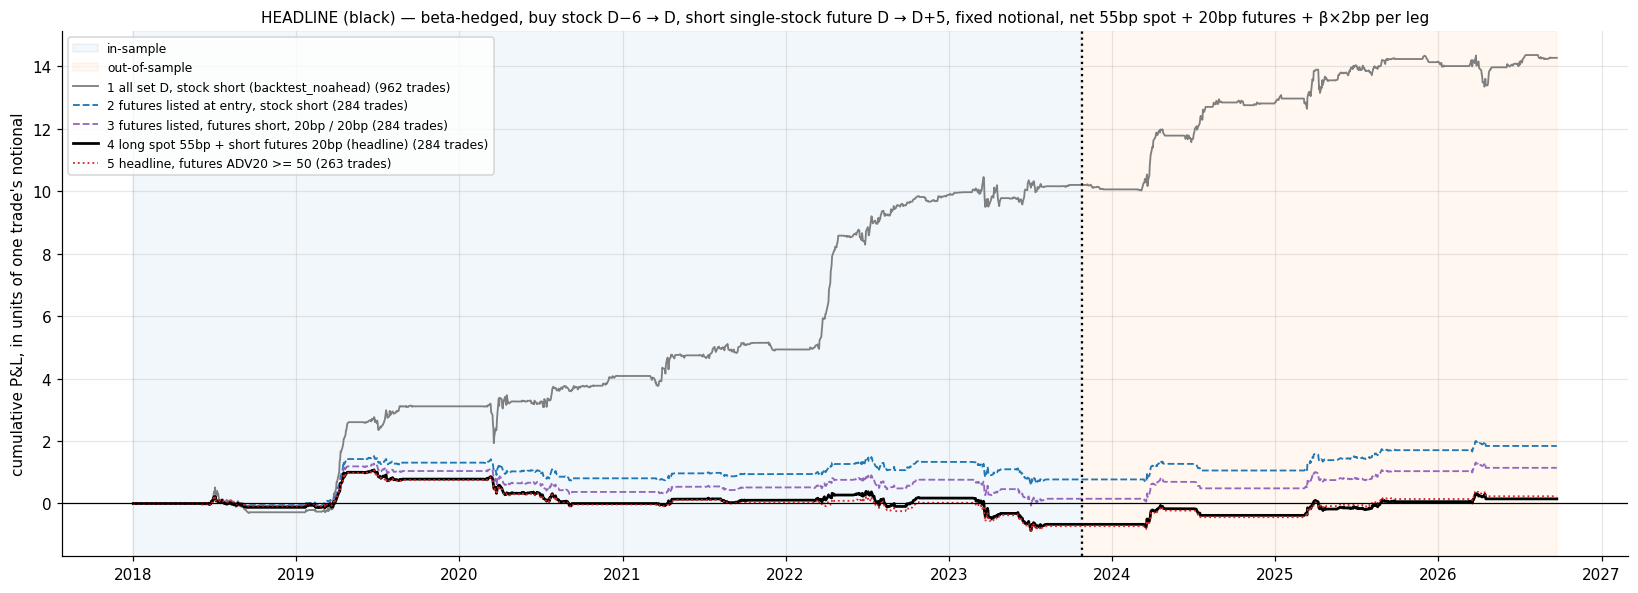

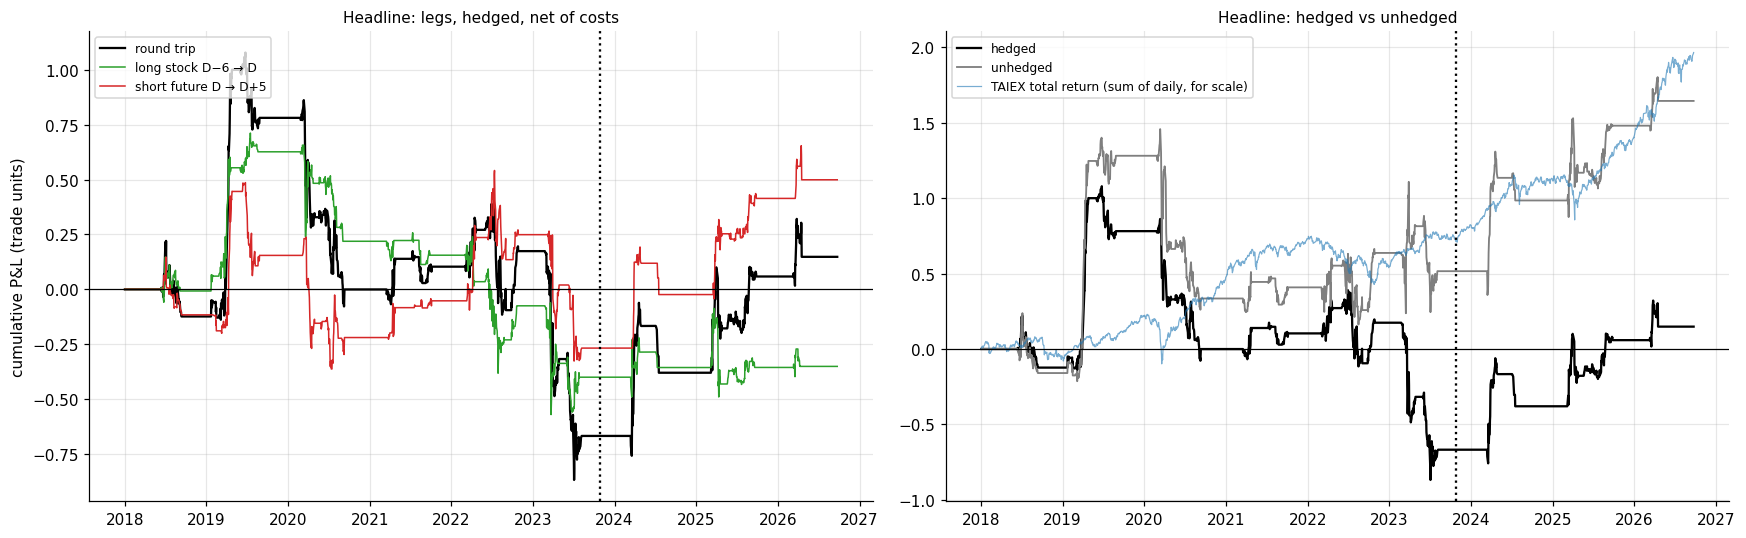

In [6]:
is_day = np.arange(T) < CUT
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.axvspan(cal[0], cal[CUT - 1], color="C0", alpha=.06, label="in-sample")
ax.axvspan(cal[CUT], cal[-1], color="C1", alpha=.06, label="out-of-sample")
for (nm, r), c, lw, ls in zip(RUNS.items(), ["C7", "C0", "C4", "k", "C3"], [1.2, 1.2, 1.2, 1.8, 1.2], ["-", "--", "--", "-", ":"]):
    ax.plot(cal, r["fixed"].cumsum(), color=c, lw=lw, ls=ls, label=f"{nm} ({len(SETS[nm][0])} trades)")
ax.axvline(cal[CUT], color="k", ls=":"); ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("cumulative P&L, in units of one trade's notional")
ax.set_title(f"HEADLINE (black) — beta-hedged, buy stock D−{K} → D, short single-stock future D → D+{H}, fixed notional, "
             f"net {COST_SPOT_LONG_BPS}bp spot + {COST_FUT_SHORT_BPS}bp futures + β×{HEDGE_BPS}bp per leg", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

rh = RUNS[HEAD]
days = F.D.values[:, None] + OFF[None, :]
b = rh["beta"]
rs = np.nan_to_num(Rv[days, F.j.values[:, None]]); rs[:, OFF >= 1] = FUT_R
pnl = SIGN[None, :] * (rs - b[:, None] * HEDGE_R[days])
pnl[:, OFF == 0] -= (COST_SPOT_LONG_BPS / 1e4 + np.abs(b) * hcost)[:, None]
pnl[:, OFF == H] -= (COST_FUT_SHORT_BPS / 1e4 + np.abs(b) * hcost)[:, None]
long_d = pd.Series(0.0, cal); short_d = pd.Series(0.0, cal)
np.add.at(long_d.values, days[:, OFF <= 0].ravel(), pnl[:, OFF <= 0].ravel())
np.add.at(short_d.values, days[:, OFF >= 1].ravel(), pnl[:, OFF >= 1].ravel())
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
a = ax[0]
a.plot(cal, rh["fixed"].cumsum(), color="k", lw=1.5, label="round trip")
a.plot(cal, long_d.cumsum(), color="C2", lw=1, label=f"long stock D−{K} → D")
a.plot(cal, short_d.cumsum(), color="C3", lw=1, label=f"short future D → D+{H}")
a.axvline(cal[CUT], color="k", ls=":"); a.axhline(0, color="k", lw=.8)
a.set_title("Headline: legs, hedged, net of costs", fontsize=10); a.legend(fontsize=8, loc="upper left"); a.set_ylabel("cumulative P&L (trade units)")
a = ax[1]
a.plot(cal, rh["fixed"].cumsum(), color="k", lw=1.5, label="hedged")
a.plot(cal, H_UNH["fixed"].cumsum(), color="C7", lw=1.2, label="unhedged")
a.plot(cal, np.cumsum(taiex), color="C0", lw=.8, alpha=.6, label="TAIEX total return (sum of daily, for scale)")
a.axvline(cal[CUT], color="k", ls=":"); a.axhline(0, color="k", lw=.8)
a.set_title("Headline: hedged vs unhedged", fontsize=10); a.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

## 7. Statistics
**What this does.** For each run and period: fixed-notional Sharpe, total P&L and max drawdown in trade units, trades,
mean net bp per trade and per leg, hit rate, t-stat across deadline dates, and correlation with TAIEX. Then the
headline by source (ex-div vs AGM) and by year.

In [7]:
rows = {}
for nm, r in list(RUNS.items()) + [("H headline unhedged", H_UNH)]:
    df = SETS[nm][0] if nm in SETS else F
    for per, dm in [("in-sample", is_day), ("out-of-sample", ~is_day)]:
        tm = (df.period == per).values
        fx = r["fixed"][dm]; eq = fx.cumsum(); op = dm & (r["npos"].values > 0)
        pdm = pd.Series(r["net"][tm]).groupby(df.Ddate.values[tm]).mean()
        rows[(nm[:1], per)] = {
            "fixed-notional Sharpe": sharpe(fx), "total P&L (trade units)": fx.sum(), "max drawdown (trade units)": (eq - eq.cummax()).min(),
            "trades": tm.sum(), "deadline dates": len(pdm), "mean net / trade bp": r["net"][tm].mean() * 1e4,
            "long leg / trade bp": r["long"][tm].mean() * 1e4, "short leg / trade bp": r["short"][tm].mean() * 1e4,
            "hit rate": (r["net"][tm] > 0).mean(), "t (per date)": pdm.mean() / pdm.std() * np.sqrt(len(pdm)),
            "corr with TAIEX": np.corrcoef(r["fixed"].values[op], taiex[op])[0, 1]}
print("runs:", {nm[:1]: nm for nm in SETS} | {"H": "headline unhedged"})
print(pd.DataFrame(rows).round(3).to_string())

print("\nheadline by source and period (mean net bp per trade, trades):")
g = pd.DataFrame({"net": rh["net"] * 1e4, "long": rh["long"] * 1e4, "short": rh["short"] * 1e4, "src": F.src, "period": F.period})
print(g.groupby(["src", "period"]).agg(trades=("net", "size"), net=("net", "mean"), long=("long", "mean"), short=("short", "mean")).round(1).to_string())

yr = []
for y, gy in F.groupby(F.Ddate.dt.year):
    dm = cal.year == y; tm = (F.Ddate.dt.year == y).values
    yr.append({"year": y, "trades": len(gy), "mean net bp": rh["net"][tm].mean() * 1e4, "long bp": rh["long"][tm].mean() * 1e4,
               "short bp": rh["short"][tm].mean() * 1e4, "hit": (rh["net"][tm] > 0).mean(), "Sharpe": sharpe(rh["fixed"][dm]),
               "period": "/".join(sorted(gy.period.unique()))})
print("\nheadline by year:")
print(pd.DataFrame(yr).set_index("year").round(2).to_string())

runs: {'1': '1 all set D, stock short (backtest_noahead)', '2': '2 futures listed at entry, stock short', '3': '3 futures listed, futures short, 20bp / 20bp', '4': '4 long spot 55bp + short futures 20bp (headline)', '5': '5 headline, futures ADV20 >= 50', 'H': 'headline unhedged'}
                                   1                       2                       3                       4                       5                       H              
                           in-sample out-of-sample in-sample out-of-sample in-sample out-of-sample in-sample out-of-sample in-sample out-of-sample in-sample out-of-sample
fixed-notional Sharpe          1.704         1.439     0.303         1.093     0.059         0.988    -0.261         0.815    -0.290         0.990     0.155         0.965
total P&L (trade units)       10.200         4.070     0.770         1.072     0.152         0.990    -0.667         0.815    -0.726         0.958     0.516         1.128
max drawdown (trade units)    -1.2

**Interpretation.**
- **Only about a third of the events are tradable this way.** 234 of 738 in-sample (32%) and 50 of 224 out-of-sample
  (22%) set-D events had a future listed at the entry. Checking against today's TAIFEX list would have said 286 / 53:
  59 events have futures that were listed only after the trade, and 4 events are on futures delisted since.
- **Selection is the biggest hit.** On the futures-listed subset with the old stock-return short (run 2), in-sample
  falls from +138bp per trade (Sharpe 1.70) to **+33bp (Sharpe 0.30, t = 0.5)**. The noahead result comes mostly from
  stocks without a future, which tend to be smaller. Out-of-sample the subset does fine (+214bp, Sharpe 1.09), but on
  only 50 trades over 32 dates (t = 0.7).
- **The futures short is a little worse than the stock short.** The futures and stock returns track each other
  (daily corr 0.97, median gap 33bp). Over D→D+5 the future gains on the stock by about +5bp a day. That is +30bp per
  AGM event and +17bp per ex-div event (mean; median 14bp / 0bp), all of it against the short. In-sample the short leg
  goes from +15bp to −11bp. One possible reason, not tested: during the ban, short demand moves into futures and makes
  them cheap at D, and that basis then normalises.
- **The dividend adjustment matters and works.** 113 ex-dates fall inside short windows. After the adjustment, the
  futures-vs-stock gap on those days is 40bp; without it, it is 393bp, which would book the dividend as fake short
  profit.
- **Headline (long spot 55bp, short futures 20bp):** in-sample **−29bp per trade, Sharpe −0.26**; out-of-sample
  **+163bp, Sharpe 0.82, t = 0.2** on 50 trades. Keeping only liquid futures (≥ 50 contracts/day, 93% of trades)
  changes little. Every chosen contract traded on D, and 99% traded on D+5.
- **By source, in-sample:** ex-div events lose 124bp per trade and AGM events make 37bp. Out-of-sample both are
  positive, but on 16 and 34 trades.
- **Conclusion:** the trade that can actually be placed with a futures short has no in-sample edge. The
  out-of-sample gain is too thin to tell apart from noise. The edge in `backtest_noahead.ipynb` sits in stocks without
  a future, where the short at D can't be placed. For those names, `backtest_spot.ipynb` (margin short at E+1) is the
  placeable version.
- **Not modelled:** settlement price vs a fill at the 13:45 futures close (the stock closes at 13:30), futures
  margin, and the bid/ask on thin contracts beyond the flat 20bp.